# Road Accident Severity in Great Britain, 2005–2015

**Author:** Mayur More

An academic exploratory analysis of police-reported personal-injury accidents. The consultancy client is a hypothetical scenario. This project compares accident counts and severity shares; it does not train a prediction model.

## 1. Business context

This academic scenario considers how a road-safety consultancy might help councils investigate recorded accident patterns. Descriptive associations can identify questions for further investigation, but do not establish effective interventions or causal effects.

## 2. Dataset description and source

The analysis uses [UK Car Accidents 2005–2015 on Kaggle](https://www.kaggle.com/datasets/silicon99/dft-accident-data), attributed to Department for Transport STATS19 records. Required inputs are `Accidents0515.csv`, `Vehicles0515.csv`, `Casualties0515.csv`, and the supplied `contextCSVs` lookups which are in downloaded dataset from `archive.zip`. Download and keep the zip file or extract the CSVs beside this notebook before running. See [data provenance and setup](docs/DATA.md).

### Data dictionary

Accidents have one row per `Accident_Index`; vehicles and casualties have their own row units and can repeat that accident key. Severity codes 1/2/3 mean Fatal/Serious/Slight. The ten lookups used by the code are retained in `contextCSVs`. See `docs/DATA.md` for the input fields and definitions.

### Workflow overview

Load selected columns → check missing values and accident keys → map categorical codes → derive year, hour and severity indicators → analyse at accident, vehicle-involvement or casualty level → communicate descriptive findings with limitations. The detailed workflow follows below.

In [18]:
from pathlib import Path
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 80)
sns.set_theme(style="whitegrid", palette="Set2")

DATA_DIR = Path(".")
ARCHIVE = DATA_DIR / "archive.zip"
required = ["Accidents0515.csv", "Vehicles0515.csv", "Casualties0515.csv"]

if not all((DATA_DIR / f).exists() for f in required):
    if ARCHIVE.exists():
        with zipfile.ZipFile(ARCHIVE) as z:
            z.extractall(DATA_DIR)
        print("archive.zip extracted.")
    else:
        raise FileNotFoundError("Place the unzipped CSV files or archive.zip in the notebook folder.")

ACC_FILE, VEH_FILE, CAS_FILE = [next(DATA_DIR.rglob(f)) for f in required]
CTX_DIR = next(DATA_DIR.rglob("contextCSVs"))

files = [ACC_FILE, VEH_FILE, CAS_FILE]
display(pd.DataFrame({
    "file": [p.name for p in files],
    "exists": [p.exists() for p in files],
    "size_mb": [round(p.stat().st_size / 1e6, 1) for p in files],
    "path_used": [str(p) for p in files]
}))

,file,exists,size_mb,path_used
0,Accidents0515.csv,True,244.5,Accidents0515.csv
1,Vehicles0515.csv,True,206.8,Vehicles0515.csv
2,Casualties0515.csv,True,108.3,Casualties0515.csv


### Cleaning and feature engineering workflow

The workflow starts with the raw Kaggle files, checks data quality, creates readable analysis fields, and then answers the business questions. This is an explanatory workflow, so the notebook avoids guessing missing values or changing the original meaning of the data.

```text
Raw Kaggle data files
  Accidents0515.csv      one row per accident
  Vehicles0515.csv       one row per vehicle involved
  Casualties0515.csv     one row per casualty
  contextCSVs/           lookup tables for coded categories
        |
        v
1. Load only required columns
   Keep the notebook focused and reduce memory use.
        |
        v
2. Check data quality
   Check true NaN values with isna().
   Check coded missing/unknown values using coded_minus1.
   Confirm Accident_Index has no duplicate accident rows.
        |
        v
3. Handle missing and unknown values
   Leave rare true NaN values as missing.
   Keep coded unknown values and label them where possible.
   Do not fill missing values with guessed values.
        |
        v
4. Create analysis features
   Year from Date, Hour from Time.
   Readable labels from numeric codes.
   Severe flag for Fatal or Serious accidents.
   Junction_Group for junction vs non-junction accidents.
   User_Group and KSI for vulnerable-road-user analysis.
        |
        v
5. Analyse at the correct level
   Accident questions use unique Accident_Index counts.
   Vehicle questions avoid repeated vehicle-type counts.
   Casualty questions use casualty rows and KSI rates.
        |
        v
6. Produce EDA outputs
   Tables, charts, severe_rate_pct, ksi_rate_pct, and business interpretation.
        |
        v
7. Final recommendations
   Translate the strongest patterns into road-safety actions.
```

In the summary tables, `accidents` means unique accident count, `severe_accidents` means Fatal or Serious accidents, and `severe_rate_pct` means `severe_accidents / accidents * 100`. For casualty analysis, `KSI` means killed or seriously injured, and `ksi_rate_pct` means `killed_or_serious / casualties * 100`.


## 3. Initial data exploration

In [2]:
def lookup(file_name):
    path = CTX_DIR / file_name
    if not path.exists():
        return pd.Series(dtype="object")
    return pd.read_csv(path).set_index("code")["label"]

lookups = {
    "Accident_Severity": lookup("Accident_Severity.csv"),
    "Casualty_Severity": lookup("Casualty_Severity.csv"),
    "Casualty_Type": lookup("Casualty_Type.csv"),
    "Day_of_Week": lookup("Day_of_Week.csv"),
    "Junction_Detail": lookup("Junction_Detail.csv"),
    "Light_Conditions": lookup("Light_Conditions.csv"),
    "Police_Force": lookup("Police_Force.csv"),
    "Road_Type": lookup("Road_Type.csv"),
    "Urban_or_Rural_Area": lookup("Urban_Rural.csv"),
    "Vehicle_Type": lookup("Vehicle_Type.csv"),
}
lookups["Weather_Conditions"] = pd.Series({1:"Fine",2:"Rain",3:"Snow",4:"Fine/high wind",5:"Rain/high wind",6:"Snow/high wind",7:"Fog/mist",8:"Other",9:"Unknown",-1:"Missing"})
lookups["Road_Surface_Conditions"] = pd.Series({1:"Dry",2:"Wet/damp",3:"Snow",4:"Frost/ice",5:"Flood",6:"Oil/diesel",7:"Mud",-1:"Missing"})

def add_label(df, col):
    mapper = lookups.get(col)
    if mapper is not None and not mapper.empty:
        df[col + "_label"] = df[col].map(mapper).fillna("Not mapped")
    return df

def accident_summary(df, by):
    out = df.groupby(by, dropna=False).agg(accidents=("Accident_Index", "nunique"), severe_accidents=("Severe", "sum"))
    out["severe_rate_pct"] = (100 * out["severe_accidents"] / out["accidents"]).round(2)
    return out

def top_rows(df, n=12, by="accidents"):
    return df.sort_values(by, ascending=False).head(n)

In [3]:
acc_cols = ["Accident_Index","Accident_Severity","Number_of_Vehicles","Number_of_Casualties","Date","Day_of_Week","Time","Police_Force","Road_Type","Speed_limit","Junction_Detail","Light_Conditions","Weather_Conditions","Road_Surface_Conditions","Urban_or_Rural_Area","Longitude","Latitude"]
veh_cols = ["Accident_Index","Vehicle_Reference","Vehicle_Type"]
cas_cols = ["Accident_Index","Vehicle_Reference","Casualty_Reference","Casualty_Severity","Casualty_Type","Casualty_Class"]

acc = pd.read_csv(ACC_FILE, usecols=acc_cols, parse_dates=["Date"], dayfirst=True, low_memory=False)
veh = pd.read_csv(VEH_FILE, usecols=veh_cols, low_memory=False)
cas = pd.read_csv(CAS_FILE, usecols=cas_cols, low_memory=False)

acc["Year"] = acc["Date"].dt.year
acc["Hour"] = pd.to_datetime(acc["Time"], format="%H:%M", errors="coerce").dt.hour.astype("Int64")
acc["Severe"] = acc["Accident_Severity"].isin([1, 2])

for col in ["Accident_Severity","Day_of_Week","Urban_or_Rural_Area","Road_Type","Light_Conditions","Weather_Conditions","Road_Surface_Conditions","Police_Force","Junction_Detail"]:
    add_label(acc, col)

display(pd.DataFrame({"table": ["accidents", "vehicles", "casualties"], "rows": [len(acc), len(veh), len(cas)], "columns": [acc.shape[1], veh.shape[1], cas.shape[1]]}))
display(acc.head(3))

,table,rows,columns
0,accidents,1780653,29
1,vehicles,3262270,3
2,casualties,2402909,6


The accident table contains 1,780,653 unique accident records from 1 January 2005 to 31 December 2015. The vehicle and casualty tables are larger because a single accident can involve multiple vehicles and multiple injured people. Therefore, accident-level questions use unique `Accident_Index` counts, while vehicle and casualty questions are handled separately to avoid double counting.


## 4. Data quality issues

In [4]:
coded_minus1 = acc.select_dtypes(include="number").eq(-1).sum()
quality = pd.DataFrame({
    "missing_pct": (acc.isna().mean() * 100).round(3),
    "coded_minus1": coded_minus1.reindex(acc.columns, fill_value=0),
    "unique_values": acc.nunique()
}).sort_values(["missing_pct", "coded_minus1"], ascending=False)

display(quality.head(15))
print("Duplicate Accident_Index rows:", acc["Accident_Index"].duplicated().sum())
print("Date range:", acc["Date"].min().date(), "to", acc["Date"].max().date())

,missing_pct,coded_minus1,unique_values
Longitude,0.008,1,1246102
Latitude,0.008,0,1168981
Time,0.008,0,1439
Hour,0.008,0,24
Road_Surface_Conditions,0.000,2439,6
Weather_Conditions,0.000,161,10
Junction_Detail,0.000,19,10
Accident_Index,0.000,0,1780653
Police_Force,0.000,0,51
Accident_Severity,0.000,0,3


Duplicate Accident_Index rows: 0
Date range: 2005-01-01 to 2015-12-31


The main accident table has very few real missing or `NaN` values: longitude, latitude, time, and the derived hour are missing for about 0.008% of rows. The column `missing_pct` measures these true blank/NaN values using `isna()`. The column `coded_minus1` is different: it counts numeric values recorded as `-1`, which the data guide uses for missing, unknown, or out-of-range categories. These were not imputed because they are rare and sometimes meaningful as an "unknown" category; instead, the analysis labels them where possible and filters very small groups when ranking rates. `Accident_Index` has no duplicates, which supports accident-level grouping. The main analytical risk is double counting after merges, because joining vehicle or casualty rows can repeat the same accident.


## 5. Data preprocessing

In [5]:
severity_order = ["Fatal", "Serious", "Slight"]
display(acc["Accident_Severity_label"].value_counts().reindex(severity_order))

acc["Junction_Group"] = np.select(
    [acc["Junction_Detail"].eq(0), acc["Junction_Detail"].gt(0)],
    ["Non-junction", "Junction or near junction"],
    default="Unknown"
)

Accident_Severity_label
Fatal        22998
Serious     242080
Slight     1515575
Name: count, dtype: int64

## 6. EDA business questions

### Q1. How did accident volume and severity change from 2005 to 2015?

,accidents,severe_accidents,severe_rate_pct,accident_change_from_2005_pct,severe_accidents_from_2005_pct
Year,,,,,
2005,198735,27942,14.06,0.00,0.00
2006,189161,27872,14.73,-4.82,-0.25
2007,182115,27036,14.85,-8.36,-3.24
2008,170591,25462,14.93,-14.16,-8.88
2009,163554,24054,14.71,-17.70,-13.91
2010,154414,22171,14.36,-22.30,-20.65
2011,151474,22783,15.04,-23.78,-18.46
2012,145571,22538,15.48,-26.75,-19.34
2013,138660,21232,15.31,-30.23,-24.01


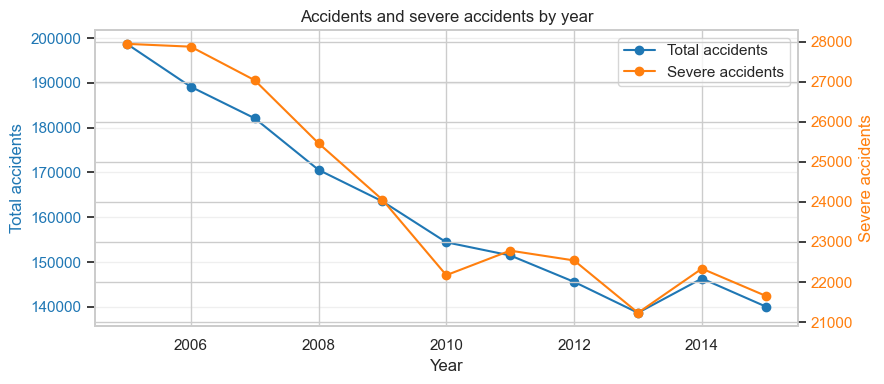

In [6]:
q1 = accident_summary(acc, "Year").sort_index()
q1["accident_change_from_2005_pct"] = (100 * (q1["accidents"] / q1.loc[2005, "accidents"] - 1)).round(2)
q1["severe_accidents_from_2005_pct"] = (100 * (q1["severe_accidents"] / q1.loc[2005, "severe_accidents"] - 1)).round(2)
display(q1)

fig, ax1 = plt.subplots(figsize=(9,4))
ax2 = ax1.twinx()

line1 = ax1.plot(q1.index, q1["accidents"], color="tab:blue", marker="o", label="Total accidents")
line2 = ax2.plot(q1.index, q1["severe_accidents"], color="tab:orange", marker="o", label="Severe accidents")

ax1.set_title("Accidents and severe accidents by year")
ax1.set_xlabel("Year")
ax1.set_ylabel("Total accidents", color="tab:blue")
ax2.set_ylabel("Severe accidents", color="tab:orange")
ax1.tick_params(axis="y", labelcolor="tab:blue")
ax2.tick_params(axis="y", labelcolor="tab:orange")

lines = line1 + line2
labels = [line.get_label() for line in lines]
ax1.legend(lines, labels, loc="upper right")
ax1.grid(True, axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

### Q1 Answer

Recorded accidents fell from 198,735 in 2005 to 140,056 in 2015 (−29.53%). Severe accidents fell from 27,942 to 21,654 (−22.50%), while their share increased from 14.06% to 15.46%. Count trends and severity shares answer different questions; neither is an exposure-adjusted collision risk.

### Q2. Which days and hours have the highest accident frequency?

accidents
Day_of_Week_label Hour           
Wednesday         17        26531
Tuesday           17        26489
Friday            17        25783
Thursday          17        25775
Wednesday         8         25432
Tuesday           8         25368
Friday            16        24821
                  15        24718
Thursday          8         24368
Monday            17        24148

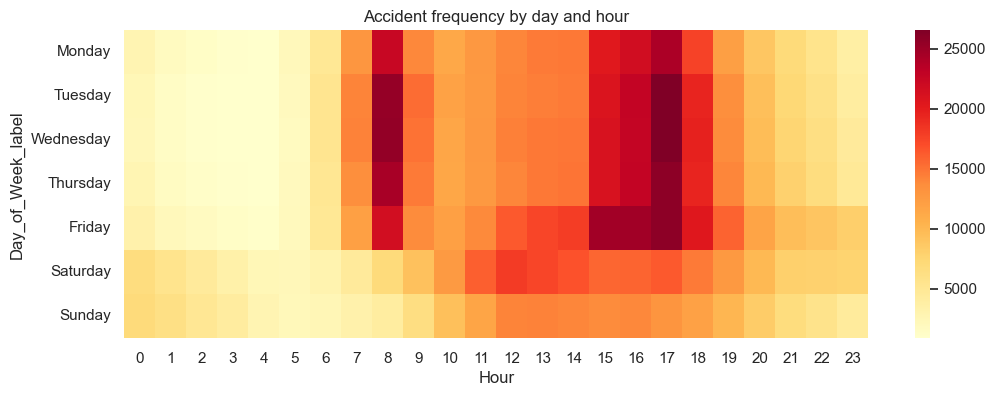

In [7]:
day_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
q2 = acc.pivot_table(index="Day_of_Week_label", columns="Hour", values="Accident_Index", aggfunc="count").reindex(day_order)
display(acc.groupby(["Day_of_Week_label", "Hour"]).size().sort_values(ascending=False).head(10).to_frame("accidents"))
plt.figure(figsize=(12,4))
sns.heatmap(q2, cmap="YlOrRd")
plt.title("Accident frequency by day and hour")
plt.show()

### Q2 Answer

The largest recorded day/hour counts occur in weekday commuting periods, around 17:00 and 08:00. Wednesday at 17:00 has 26,531 accidents in the saved table. Traffic exposure is not measured, so this identifies high recorded volumes rather than the most dangerous travel times.

### Q3. Are severe accidents more common in urban or rural areas?

,accidents,severe_accidents,severe_rate_pct
Urban_or_Rural_Area_label,,,
Urban,1146421,148558,12.96
Rural,634089,116501,18.37
Unallocated,143,19,13.29


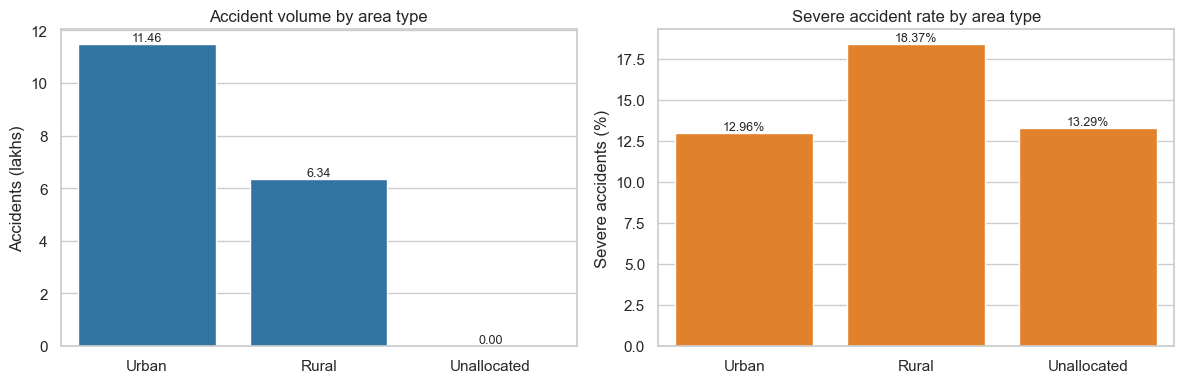

In [8]:
q3 = accident_summary(acc, "Urban_or_Rural_Area_label").reindex(["Urban", "Rural", "Unallocated"])
display(q3)

q3_plot = q3.reset_index().assign(accidents_lakh=lambda x: x["accidents"] / 100000)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=q3_plot, x="Urban_or_Rural_Area_label", y="accidents_lakh", ax=ax[0], color="tab:blue")
ax[0].set(title="Accident volume by area type", xlabel="", ylabel="Accidents (lakhs)")

sns.barplot(data=q3_plot, x="Urban_or_Rural_Area_label", y="severe_rate_pct", ax=ax[1], color="tab:orange")
ax[1].set(title="Severe accident rate by area type", xlabel="", ylabel="Severe accidents (%)")

for axis, col, suffix in [(ax[0], "accidents_lakh", ""), (ax[1], "severe_rate_pct", "%")]:
    for i, value in enumerate(q3_plot[col]):
        axis.text(i, value, f"{value:.2f}{suffix}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

### Q3 Answer

Urban areas have 1,146,421 recorded accidents and a 12.96% severe share; rural areas have 634,089 and an 18.37% severe share. The 143 unallocated cases remain in the displayed table. The contrast is conditional on reported accidents and is not a comparison of per-trip rural and urban risk.

### Q4. How do weather and road surface conditions relate to accident severity?

In [9]:
q4 = accident_summary(acc, ["Weather_Conditions_label", "Road_Surface_Conditions_label"])
q4 = q4.query("accidents >= 1000").sort_values("severe_rate_pct", ascending=False)
display(q4.head(12))

,,accidents,severe_accidents,severe_rate_pct
Weather_Conditions_label,Road_Surface_Conditions_label,,,
Fog/mist,Dry,1477,283,19.16
Fine/high wind,Dry,13741,2400,17.47
Fog/mist,Wet/damp,6806,1140,16.75
Fine,Wet/damp,222789,35937,16.13
Fine/high wind,Wet/damp,9065,1448,15.97
Rain,Flood,1334,213,15.97
Fine,Dry,1176234,179052,15.22
Rain/high wind,Wet/damp,24663,3646,14.78
Fine,Frost/ice,21511,2915,13.55


### Q4 Answer

Among weather/surface combinations with at least 1,000 accidents, fog/mist on dry surfaces has a 19.16% severe share. Fine/dry conditions account for 1,176,234 accidents and 179,052 severe accidents. This is a comparison of combinations, not evidence that weather independently causes severity.

### Q5. Do lighting conditions affect severe accidents?

,accidents,severe_accidents,severe_rate_pct
Light_Conditions_label,,,
Darkness - no lighting,98947,23594,23.85
Darkness - lights unlit,8185,1398,17.08
Darkness - lights lit,349728,56837,16.25
Darkness - lighting unknown,19319,2729,14.13
Daylight,1304474,180520,13.84


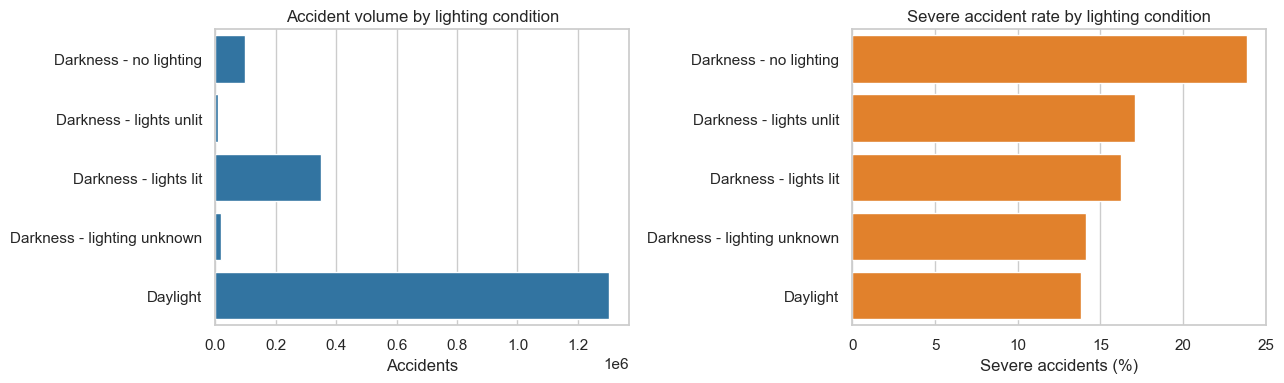

In [10]:
q5 = top_rows(accident_summary(acc, "Light_Conditions_label"), by="severe_rate_pct")
display(q5)

q5_plot = q5.reset_index()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

sns.barplot(data=q5_plot, y="Light_Conditions_label", x="accidents", ax=ax[0], color="tab:blue")
ax[0].set(title="Accident volume by lighting condition", xlabel="Accidents", ylabel="")

sns.barplot(data=q5_plot, y="Light_Conditions_label", x="severe_rate_pct", ax=ax[1], color="tab:orange")
ax[1].set(title="Severe accident rate by lighting condition", xlabel="Severe accidents (%)", ylabel="")

plt.tight_layout()
plt.show()

### Q5 Answer

Daylight accounts for 1,304,474 accidents, with a 13.84% severe share. Darkness without lighting accounts for 98,947, with a 23.85% severe share. Road type, speed, exposure and other factors are not controlled; lighting interventions require additional evidence.

### Q6. Which road types or speed limits are linked with higher severity?

,accidents,severe_accidents,severe_rate_pct
Road_Type_label,,,
Single carriageway,1332384,209922,15.76
Dual carriageway,262950,36308,13.81
One way street,36755,4870,13.25
Unknown,10445,1214,11.62
Slip road,18647,1815,9.73
Roundabout,119472,10949,9.16


,accidents,severe_accidents,severe_rate_pct
Speed_limit,,,
0,1,0,0.00
10,19,5,26.32
15,16,1,6.25
20,22017,3295,14.97
30,1141609,149340,13.08
40,146292,22067,15.08
50,58505,9897,16.92
60,282363,61826,21.90
70,129831,18647,14.36


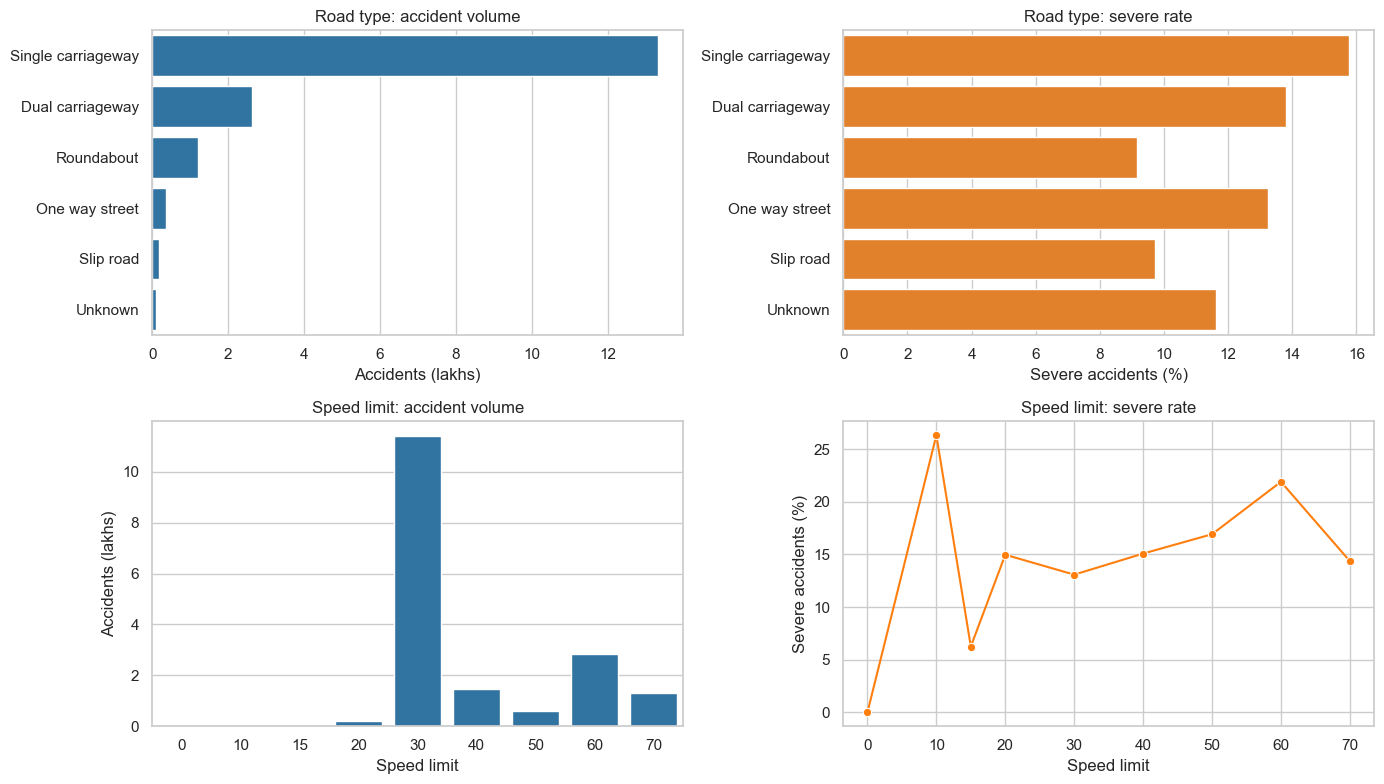

In [11]:
q6a = accident_summary(acc, "Road_Type_label").query("accidents >= 1000").sort_values("severe_rate_pct", ascending=False)
q6b = accident_summary(acc, "Speed_limit").sort_values("Speed_limit")

display(q6a)
display(q6b)

q6a_plot = q6a.reset_index().assign(accidents_lakh=lambda x: x["accidents"] / 100000)
q6b_plot = q6b.reset_index().assign(accidents_lakh=lambda x: x["accidents"] / 100000)

fig, ax = plt.subplots(2, 2, figsize=(14, 8))

sns.barplot(data=q6a_plot.sort_values("accidents", ascending=False), y="Road_Type_label", x="accidents_lakh", ax=ax[0,0], color="tab:blue")
sns.barplot(data=q6a_plot.sort_values("accidents", ascending=False), y="Road_Type_label", x="severe_rate_pct", ax=ax[0,1], color="tab:orange")
sns.barplot(data=q6b_plot, x="Speed_limit", y="accidents_lakh", ax=ax[1,0], color="tab:blue")
sns.lineplot(data=q6b_plot, x="Speed_limit", y="severe_rate_pct", marker="o", ax=ax[1,1], color="tab:orange")

titles = ["Road type: accident volume", "Road type: severe rate", "Speed limit: accident volume", "Speed limit: severe rate"]
xlabels = ["Accidents (lakhs)", "Severe accidents (%)", "Speed limit", "Speed limit"]
ylabels = ["", "", "Accidents (lakhs)", "Severe accidents (%)"]

for axis, title, xlabel, ylabel in zip(ax.ravel(), titles, xlabels, ylabels):
    axis.set(title=title, xlabel=xlabel, ylabel=ylabel)

plt.tight_layout()
plt.show()

### Q6 Answer

Single carriageways account for 1,332,384 accidents and a 15.76% severe share. Among common speed-limit groups, 60 mph roads have a 21.90% severe share, while 30 mph roads account for 1,141,609 accidents. The speed limit is a recorded road attribute, not a measurement of vehicle speed. Small groups should not be over-interpreted. A lakh in the unchanged charts means 100,000.

### Q7. Which vehicle types are most involved in serious/fatal accidents?

In [12]:
veh_acc = veh.merge(acc[["Accident_Index", "Severe"]], on="Accident_Index", how="inner")
add_label(veh_acc, "Vehicle_Type")
veh_acc_unique = veh_acc.drop_duplicates(["Accident_Index", "Vehicle_Type_label"])
q7 = accident_summary(veh_acc_unique, "Vehicle_Type_label").query("accidents >= 500")
display(q7.sort_values("severe_accidents", ascending=False).head(12))
display(q7.sort_values("severe_rate_pct", ascending=False).head(12))

,accidents,severe_accidents,severe_rate_pct
Vehicle_Type_label,,,
Car,1544623,209505,13.56
Motorcycle over 500cc,91647,33353,36.39
Pedal cycle,200996,33246,16.54
Van / Goods 3.5 tonnes mgw or under,144011,19581,13.60
Motorcycle 125cc and under,78607,17410,22.15
Goods 7.5 tonnes mgw and over,63208,11945,18.90
Bus or coach (17 or more pass seats),81088,10270,12.67
Motorcycle over 125cc and up to 500cc,27552,7874,28.58
Taxi/Private hire car,56045,7105,12.68


,accidents,severe_accidents,severe_rate_pct
Vehicle_Type_label,,,
Motorcycle over 500cc,91647,33353,36.39
Motorcycle - unknown cc,551,166,30.13
Motorcycle over 125cc and up to 500cc,27552,7874,28.58
Mobility scooter,680,165,24.26
Agricultural vehicle,6734,1616,24.00
Ridden horse,1310,293,22.37
Motorcycle 125cc and under,78607,17410,22.15
Goods 7.5 tonnes mgw and over,63208,11945,18.90
Motorcycle 50cc and under,38652,6811,17.62


### Q7 Answer

Cars appear in the largest number of severe accidents (209,505). Accidents involving motorcycles over 500cc have a 36.39% severe share (33,353 of 91,647). The code deduplicates each accident/vehicle-type combination. Types overlap within multi-vehicle accidents, and the severity belongs to the accident rather than necessarily the rider or driver.

### Q8. Are pedestrians, cyclists, or motorcyclists especially vulnerable in certain conditions?

In [13]:
cas_acc = cas.merge(acc[["Accident_Index", "Light_Conditions_label", "Urban_or_Rural_Area_label"]], on="Accident_Index", how="inner")
cas_acc["User_Group"] = np.select(
    [cas_acc["Casualty_Type"].eq(0), cas_acc["Casualty_Type"].eq(1), cas_acc["Casualty_Type"].isin([2,3,4,5,97])],
    ["Pedestrian", "Cyclist", "Motorcyclist"], default="Other"
)
cas_acc["KSI"] = cas_acc["Casualty_Severity"].isin([1, 2])
vru = cas_acc[cas_acc["User_Group"].ne("Other")]
q8 = vru.groupby(["User_Group", "Light_Conditions_label"]).agg(casualties=("KSI", "size"), killed_or_serious=("KSI", "sum"))
q8["ksi_rate_pct"] = (100 * q8["killed_or_serious"] / q8["casualties"]).round(2)
display(q8.query("casualties >= 500").sort_values("ksi_rate_pct", ascending=False).head(15))

casualties  killed_or_serious  \
User_Group   Light_Conditions_label                                       
Pedestrian   Darkness - no lighting             5186               2369   
Motorcyclist Darkness - no lighting             6430               2821   
Cyclist      Darkness - no lighting             2342                798   
Pedestrian   Darkness - lights unlit            1621                481   
Motorcyclist Darkness - lights unlit             925                264   
             Daylight                         175905              48808   
Pedestrian   Darkness - lights lit             74204              20083   
Motorcyclist Darkness - lighting unknown        2037                522   
             Darkness - lights lit             45720              11529   
Pedestrian   Daylight                         215355              43884   
             Darkness - lighting unknown        3560                718   
Cyclist      Darkness - lights unlit             949                159   
             Darkness - lights lit             34179               5587   
             Darkness - lighting unknown        2207                357   
             Daylight                         157696              25148   

                                          ksi_rate_pct  
User_Group   Light_Conditions_label                     
Pedestrian   Darkness - no lighting              45.68  
Motorcyclist Darkness - no lighting              43.87  
Cyclist      Darkness - no lighting              34.07  
Pedestrian   Darkness - lights unlit             29.67  
Motorcyclist Darkness - lights unlit             28.54  
             Daylight                            27.75  
Pedestrian   Darkness - lights lit               27.06  
Motorcyclist Darkness - lighting unknown         25.63  
             Darkness - lights lit               25.22  
Pedestrian   Daylight                            20.38  
             Darkness - lighting unknown         20.17  
Cyclist      Darkness - lights unlit             16.75  
             Darkness - lights lit               16.35  
             Darkness - lighting unknown         16.18  
             Daylight                            15.95

### Q8 Answer

KSI means killed or seriously injured. In darkness without lighting, pedestrian KSI is 2,369 of 5,186 casualties (45.68%) and motorcyclist KSI is 2,821 of 6,430 (43.87%). These are casualty-level shares among recorded injured people, not risks among everyone walking or riding. The displayed ranking requires at least 500 casualties.

### Q9. Which police force areas have the highest accident concentration?

,accidents,severe_accidents,severe_rate_pct
Police_Force_label,,,
Metropolitan Police,264698,30967,11.70
West Midlands,74506,10084,13.53
Thames Valley,66109,9782,14.80
West Yorkshire,65835,9854,14.97
Greater Manchester,64832,8206,12.66
Kent,56155,6725,11.98
Hampshire,54380,9984,18.36
Devon and Cornwall,51106,6133,12.00
Lancashire,49514,8803,17.78


,accidents,severe_accidents,severe_rate_pct
Police_Force_label,,,
Grampian,11578,3091,26.70
Northamptonshire,16005,3670,22.93
North Yorkshire,24990,5699,22.81
Dyfed-Powys,16500,3264,19.78
Sussex,48996,9518,19.43
Hampshire,54380,9984,18.36
Humberside,28896,5257,18.19
Wiltshire,17358,3090,17.80
Lancashire,49514,8803,17.78


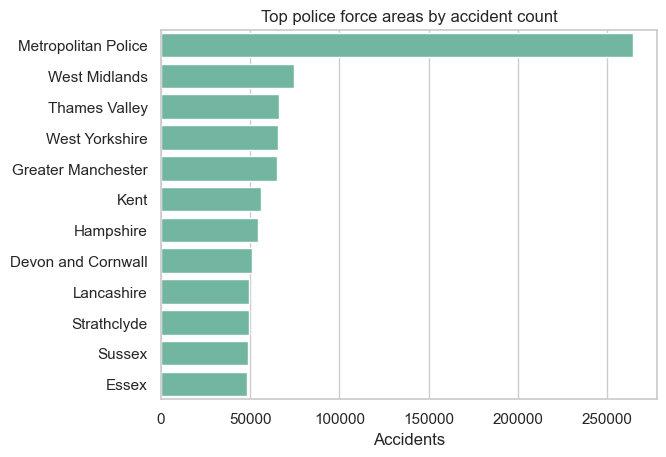

In [14]:
q9 = accident_summary(acc, "Police_Force_label")
display(q9.sort_values("accidents", ascending=False).head(15))
display(q9.query("accidents >= 10000").sort_values("severe_rate_pct", ascending=False).head(10))
sns.barplot(data=q9.sort_values("accidents", ascending=False).head(12).reset_index(), y="Police_Force_label", x="accidents")
plt.title("Top police force areas by accident count")
plt.xlabel("Accidents")
plt.ylabel("")
plt.show()

### Q9 Answer

The Metropolitan Police area has the largest recorded volume (264,698 accidents). Among areas with at least 10,000 accidents, Grampian has the highest displayed severe share (26.70%). Police boundaries, traffic volume and reporting practices differ; these rankings do not establish the safest or most dangerous region.

### Q10. Are junction accidents different from non-junction accidents?

In [15]:
q10 = accident_summary(acc, "Junction_Group").sort_values("severe_rate_pct", ascending=False)
q10_detail = accident_summary(acc, "Junction_Detail_label").sort_values("severe_rate_pct", ascending=False)
display(q10)
display(q10_detail.head(10))

,accidents,severe_accidents,severe_rate_pct
Junction_Group,,,
Non-junction,716544,128000,17.86
Junction or near junction,1064090,137076,12.88
Unknown,19,2,10.53


,accidents,severe_accidents,severe_rate_pct
Junction_Detail_label,,,
Not at junction or within 20 metres,716544,128000,17.86
Private drive or entrance,65219,9515,14.59
T or staggered junction,553692,77652,14.02
Other junction,51398,6691,13.02
Crossroads,170738,21715,12.72
More than 4 arms (not roundabout),23060,2821,12.23
Slip road,26054,3129,12.01
Data missing or out of range,19,2,10.53
Mini-roundabout,19206,1879,9.78


### Q10 Answer

Non-junction accidents have a 17.86% severe share (128,000 of 716,544), compared with 12.88% for junction/near-junction accidents (137,076 of 1,064,090). Nineteen unknown cases are retained. These descriptive differences do not identify which engineering changes would reduce severity.

## 7. Discussion and limitations

The analysis separates accident volume, severe-accident share and casualty-level KSI. It uses distinct accident keys and deduplicated vehicle-type involvements to avoid inflated denominators. Rural areas, unlit darkness, single carriageways and some motorcycle-involvement groups have higher severe shares among recorded accidents.

These findings suggest topics for further road-safety investigation, not validated policy prescriptions. No traffic, distance, population or road-length exposure is available, and confounding, reporting differences and historical changes remain. The data covers 2005–2015, not present-day conditions. No causal model, predictive estimator, intervention evaluation or professional client engagement is demonstrated. See [methods and limitations](docs/METHODS_AND_LIMITATIONS.md).

## 8. References

Department for Transport (n.d.) *Road safety data: STATS19*. Available at: https://data.gov.uk/dataset/road-accidents-safety-data.

Kaggle (2019) *DFT Accident Data*. Available at: https://www.kaggle.com/datasets/silicon99/dft-accident-data.

McKinney, W. (2010) 'Data structures for statistical computing in Python', *Proceedings of the 9th Python in Science Conference*, pp. 56-61.

Waskom, M. (2021) 'seaborn: statistical data visualization', *Journal of Open Source Software*, 6(60), p. 3021.
